In [27]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

In [28]:
A = np.array([1.0, 25.0])

def loss(w):
    return 0.5 * np.sum(A * w**2)

def grad(w):
    return A * w

# AdaGrad

In [29]:
def AdaGrad(w0, lr, epochs):
    """Accumulate squared gradients to scale each parameter update."""
    eps = 1e-8
    w = w0.copy()
    G = np.zeros_like(w0)
    path = [w.copy()]
    for _ in range(epochs):
        g = grad(w)
        G += g**2
        w = w - lr * g / (np.sqrt(G) + eps)
        path.append(w.copy())
    return np.array(path)

### Keras Implementation

In [ ]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='softmax', input_shape=(784,))
])

optimizer = tf.keras.optimizers.Adagrad(learning_rate=0.05)

# RMSProp

In [31]:
def RMSProp(w0, rho, lr, epochs):
    """Scale updates using an exponential average of squared gradients."""
    eps = 1e-8
    w = w0.copy()
    v = np.zeros_like(w0)
    path = [w.copy()]
    for _ in range(epochs):
        g = grad(w)
        v = rho * v + (1 - rho) * g**2
        w = w - lr * g / (np.sqrt(v) + eps)
        path.append(w.copy())
    return np.array(path)

### Keras Implementation

In [ ]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='softmax', input_shape=(784,))
])

optimizer = tf.keras.optimizers.RMSprop(
    learning_rate=0.001,
    rho=0.9,          # Discounting factor for the old gradients
    momentum=0.0,     # Optional momentum multiplier
    epsilon=1e-07     # Small constant for numerical stability
)

# Adam

In [32]:
def Adam(w0, beta1, beta2, lr, epochs):
    """Adam with first- and second-moment bias correction."""
    eps = 1e-8
    w = w0.copy()
    m = np.zeros_like(w0)
    v = np.zeros_like(w0)
    path = [w.copy()]
    for t in range(1, epochs + 1):
        g = grad(w)
        m = beta1 * m + (1 - beta1) * g
        v = beta2 * v + (1 - beta2) * g**2
        m_hat = m / (1 - beta1**t)
        v_hat = v / (1 - beta2**t)
        w = w - lr * m_hat / (np.sqrt(v_hat) + eps)
        path.append(w.copy())
    return np.array(path)

### Keras Implementation

In [ ]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='softmax', input_shape=(784,))
])

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001,
    beta_1=0.9,       # Exponential decay rate for the 1st moment estimates
    beta_2=0.999,     # Exponential decay rate for the 2nd moment estimates
    epsilon=1e-07     # Small constant for numerical stability
)

In [33]:
def losses(path):
    return np.array([loss(p) for p in path])


def steps_to(path, tol=1e-3):
    """First update where loss < tol; np.inf if it never gets there."""
    L = losses(path)
    if not np.all(np.isfinite(L)) or L.max() > 1e12:
        return np.inf
    hit = np.where(L < tol)[0]
    return hit[0] if len(hit) else np.inf


def run_checked(fn, *args):
    path = fn(*args)
    if not np.all(np.isfinite(path)):
        raise FloatingPointError(f"{fn.__name__} produced non-finite parameters")
    return path

In [48]:
w0 = np.array([10.0, 1.0])
lr, rho, beta1, beta2, steps = 0.05, 0.9, 0.9, 0.999, 500

adagrad = run_checked(AdaGrad, w0, lr, steps)
rmsp = run_checked(RMSProp, w0, rho, lr, steps)
adam = run_checked(Adam, w0, beta1, beta2, lr, steps)

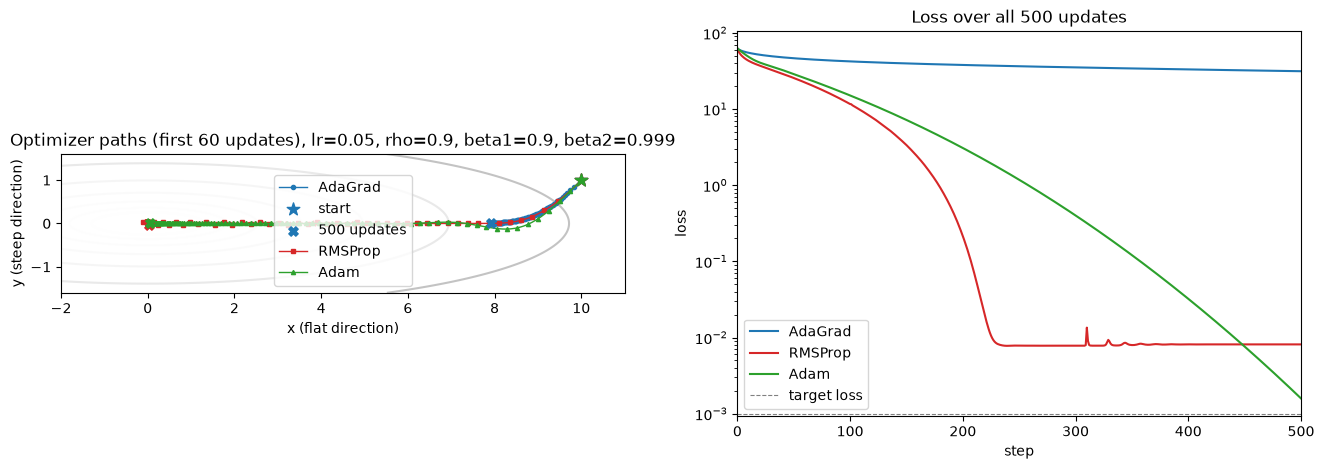

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Contours and optimizer paths: include the initial point plus 60 updates.
xs = np.linspace(-2, 11, 300)
ys = np.linspace(-1.6, 1.6, 300)
X, Y = np.meshgrid(xs, ys)
Z = 0.5 * (A[0] * X**2 + A[1] * Y**2)
levels = np.geomspace(1e-3, Z.max(), 18)
ax[0].contour(X, Y, Z, levels=levels, alpha=0.55, cmap="Greys")

for path, label, color, marker in (
    (adagrad, "AdaGrad", "tab:blue", "o"),
    (rmsp, "RMSProp", "tab:red", "s"),
    (adam, "Adam", "tab:green", "^"),
):
    shown = path[:500]
    ax[0].plot(shown[:, 0], shown[:, 1], marker + "-", ms=3, lw=1,
               markevery=5, label=label, color=color)
    ax[0].scatter(*shown[0], marker="*", s=90, color=color, zorder=4,
                   label="start" if label == "AdaGrad" else None)
    ax[0].scatter(*shown[-1], marker="X", s=45, color=color, zorder=4,
                   label="500 updates" if label == "AdaGrad" else None)

ax[0].set_title(f"Optimizer paths (first 60 updates), lr={lr}, rho={rho}, beta1={beta1}, beta2={beta2}")
ax[0].set_xlabel("x (flat direction)")
ax[0].set_ylabel("y (steep direction)")
ax[0].set_aspect("equal", adjustable="box")
ax[0].legend()

# Loss panel shows the full 200-update run, not just the trajectory window.
for path, label, color in (
    (adagrad, "AdaGrad", "tab:blue"),
    (rmsp, "RMSProp", "tab:red"),
    (adam, "Adam", "tab:green"),
):
    ax[1].semilogy(np.maximum(losses(path), np.finfo(float).tiny),
                   label=label, color=color)
ax[1].axhline(1e-3, ls="--", color="gray", lw=0.8, label="target loss")
ax[1].set_title(f"Loss over all {steps} updates")
ax[1].set_xlabel("step")
ax[1].set_ylabel("loss")
ax[1].set_xlim(0, steps)
ax[1].legend()

plt.show()